In [17]:
# Importação
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Download e Carregamento do Dataset
print("Dataset via Kagglehub")
path = kagglehub.dataset_download("zeyadmohamed26/netflix-customer-churn-and-engagement-analytics")

csv_file = [f for f in os.listdir(path) if f.endswith('.csv')][0]
caminho_completo = os.path.join(path, csv_file)

df = pd.read_csv(caminho_completo)
print(f"Dataset carregado com sucesso!\nNúmero de linhas e colunas: {df.shape}")

Dataset via Kagglehub
Dataset carregado com sucesso!
Número de linhas e colunas: (5000, 14)


In [18]:
# 2. Verificação de Valores Ausentes
print("Valores ausentes em cada atributo:")
print(df.isnull().sum())

Valores ausentes em cada atributo:
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64


**Valores Ausentes:** O dataset não tem qualquer dado em falta (todos retornaram 0 no `isnull()`). O nosso grupo não vai precisar aplicar técnicas de preenchimento ou remoção de linhas vazias.

In [19]:
# 3. Análise Estatística
display(df.describe())

,age,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,43.847400,11.649450,30.089800,13.683400,0.503000,3.024400,0.874800
std,15.501128,12.014654,17.536078,3.692062,0.500041,1.415841,2.619824
min,18.000000,0.010000,0.000000,8.990000,0.000000,1.000000,0.000000
25%,30.000000,3.337500,15.000000,8.990000,0.000000,2.000000,0.110000
50%,44.000000,8.000000,30.000000,13.990000,1.000000,3.000000,0.290000
75%,58.000000,16.030000,45.000000,17.990000,1.000000,4.000000,0.720000
max,70.000000,110.400000,60.000000,17.990000,1.000000,5.000000,98.420000


**Identificação de Outliers:** Prestando atenção à coluna `avg_watch_time_per_day` na tabela acima, o 3º quartil (75%) é de 0.72 horas, mas o valor máximo salta para impossíveis 98.42 (ninguém consegue assistir a 98 horas num só dia). Isto indica a presença de dados corrompidos ou *outliers* extremos. lidamos com estas anomalias no pré-processamento.

In [20]:
# 4. Balanceamento das Classes
print("Distribuição da classe alvo (churned):")
print(df['churned'].value_counts())

Distribuição da classe alvo (churned):
churned
1    2515
0    2485
Name: count, dtype: int64


**Balanceamento Ideal:** A média da coluna `churned` é de 0.503. Isto significa que a base de dados está bem balanceada, com cerca de 50,3% de exemplos de clientes que abandonaram e 49,7% que ficaram. Os algoritmos de classificação não sofrerão de viés de classe majoritária.

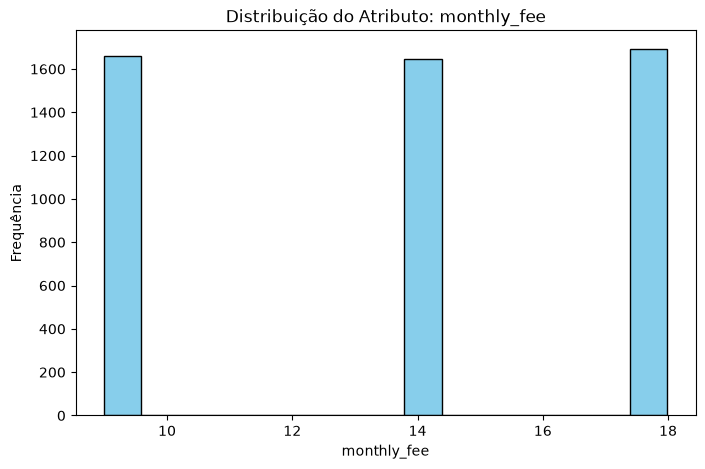

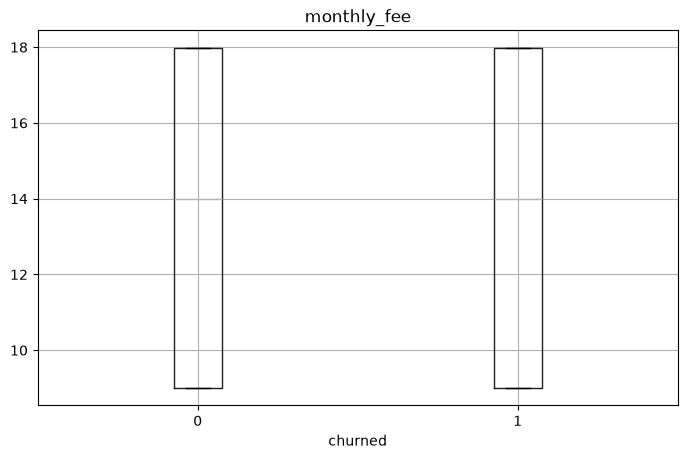

In [21]:
# 5. Estudo da Distribuição
coluna_numerica = 'monthly_fee'
coluna_alvo = 'churned'

# Histograma
plt.figure(figsize=(8, 5))
plt.hist(df[coluna_numerica].dropna(), bins=15, color='skyblue', edgecolor='black')
plt.xlabel(coluna_numerica)
plt.ylabel("Frequência")
plt.title(f"Distribuição do Atributo: {coluna_numerica}")
plt.show()

# Boxplot
df.boxplot(column=coluna_numerica, by=coluna_alvo, figsize=(8, 5))
plt.suptitle("")
plt.show()

**Análise da Mensalidade (`monthly_fee`):** 
Conforme o histograma gerado, as mensalidades agrupam-se em três faixas de valores distintos (aproximadamente $9, $14 e $18), o que reflete os planos padrão de subscrição. O *boxplot* demonstra que as caixas de dispersão e as medianas são idênticas tanto para os clientes que abandonaram (1) como para os que ficaram (0). Isto sugere que, de forma isolada, o valor da mensalidade pode não ser o fator mais determinante para o *churn* nesta base de dados específica.

## 6. Pré-Processamento de Dados

Para que os algoritmos de classificação consigam processar este conjunto de dados, precisamos transformar todas as informações numa matriz numérica (atributo-valor). Esta etapa inclui o tratamento de outliers identificados na análise exploratória, a codificação de variáveis de texto (categóricas) e a normalização das escalas.

### 6.1 Tratamento de Outliers
Como detectado na análise descritiva, a coluna `avg_watch_time_per_day` possui valores absurdos (ex: 98 horas num dia). Iremos remover estas anomalias utilizando o método do Intervalo Interquartil (IQR), que filtra os dados muito distantes da mediana, garantindo a qualidade da nossa matriz.

In [22]:
df_processado = df.copy()

# Binning (Aplicado no df_processado)
bins = [0, 18, 35, 55, 100]
labels = ['Jovem', 'Adulto', 'Meia-idade', 'Idoso']
df_processado['age_group'] = pd.cut(df_processado['age'], bins=bins, labels=labels)
df_processado.drop('age', axis=1, inplace=True)

# Tratamento de Outliers (Aplicado no df_processado)
Q1 = df_processado['avg_watch_time_per_day'].quantile(0.25)
Q3 = df_processado['avg_watch_time_per_day'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

df_processado['avg_watch_time_per_day'] = np.where(
    df_processado['avg_watch_time_per_day'] > limite_superior,
    limite_superior,
    np.where(
        df_processado['avg_watch_time_per_day'] < limite_inferior,
        limite_inferior,
        df_processado['avg_watch_time_per_day']
    )
)

### 6.2 Limpeza e Codificação de Variáveis Categóricas
A coluna `customer_id` é apenas um identificador único, não agregando valor preditivo ao modelo, logo será descartada. 
As colunas com texto (como `gender`, `subscription_type`, `region`, `device`, `payment_method`, e `favorite_genre`) precisam de ser convertidas em números. Utilizaremos a técnica **One-Hot Encoding** (através da função `get_dummies` do Pandas) para transformar estas categorias em colunas binárias (0 ou 1).

In [23]:
# Remoção da coluna de ID
df_processado = df_processado.drop('customer_id', axis=1)

# Identificação das colunas categóricas (Adicionado 'category' no filtro)
colunas_categoricas = df_processado.select_dtypes(include=['object', 'category']).columns

# Aplicação do One-Hot Encoding
df_processado = pd.get_dummies(df_processado, columns=colunas_categoricas, drop_first=True)

# Converter as colunas booleanas geradas pelo get_dummies em inteiros (0 e 1)
colunas_bool = df_processado.select_dtypes(include=['bool']).columns
df_processado[colunas_bool] = df_processado[colunas_bool].astype(int)

print("Matriz atributo-valor após codificação:")
print(f"Número de colunas aumentou para: {df_processado.shape[1]}")
df_processado.head()

Matriz atributo-valor após codificação:
Número de colunas aumentou para: 32


C:\Users\J_MiguelDev\AppData\Local\Temp\ipykernel_34428\2527158126.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_categoricas = df_processado.select_dtypes(include=['object', 'category']).columns


,watch_hours,last_login_days,monthly_fee,churned,number_of_profiles,avg_watch_time_per_day,gender_Male,gender_Other,subscription_type_Premium,subscription_type_Standard,...,payment_method_PayPal,favorite_genre_Comedy,favorite_genre_Documentary,favorite_genre_Drama,favorite_genre_Horror,favorite_genre_Romance,favorite_genre_Sci-Fi,age_group_Adulto,age_group_Meia-idade,age_group_Idoso
0,14.73,29,8.99,1,1,0.49,0,1,0,0,...,0,0,0,0,0,0,0,0,1,0
1,0.70,19,13.99,1,5,0.03,0,1,0,1,...,0,0,0,0,0,0,1,0,1,0
2,16.32,10,13.99,0,2,1.48,0,0,0,1,...,0,0,0,1,0,0,0,1,0,0
3,4.51,12,17.99,1,2,0.35,0,1,1,0,...,0,0,0,0,1,0,0,0,1,0
4,1.89,13,13.99,1,2,0.13,0,1,0,1,...,0,0,0,0,0,0,0,0,0,1


### 6.3 Normalização dos Dados
Os nossos atributos numéricos estão em escalas muito diferentes. Por exemplo, `watch_hours` tem valores dezenas de vezes maiores que `number_of_profiles`. Para evitar que algoritmos sensíveis à escala (como KNN) dem mais importância a variáveis apenas por terem números maiores, vamos normalizar as características numéricas utilizando a padronização (Média = 0, Desvio Padrão = 1).

In [24]:
from sklearn.preprocessing import StandardScaler

# Separar os atributos (X) do alvo/target (y)
X = df_processado.drop('churned', axis=1)
y = df_processado['churned']

# 'age' removido da lista de colunas numéricas
colunas_numericas_orig = ['watch_hours', 'last_login_days', 'monthly_fee', 'number_of_profiles', 'avg_watch_time_per_day']

scaler = StandardScaler()
X[colunas_numericas_orig] = scaler.fit_transform(X[colunas_numericas_orig])

print("Visualização final da Matriz Atributo-Valor Pré-processada:")
display(X.head())

# Exportar o dataset final pré-processado para entrega
df_final = pd.concat([X, y], axis=1)
df_final.to_csv('netflix_churn_pre_processado.csv', index=False)
print("csv 'netflix_churn_pre_processado.csv' pronto")

Visualização final da Matriz Atributo-Valor Pré-processada:


,watch_hours,last_login_days,monthly_fee,number_of_profiles,avg_watch_time_per_day,gender_Male,gender_Other,subscription_type_Premium,subscription_type_Standard,region_Asia,...,payment_method_PayPal,favorite_genre_Comedy,favorite_genre_Documentary,favorite_genre_Drama,favorite_genre_Horror,favorite_genre_Romance,favorite_genre_Sci-Fi,age_group_Adulto,age_group_Meia-idade,age_group_Idoso
0,0.256425,-0.062152,-1.271341,-1.429965,-0.032079,0,1,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,-0.911432,-0.632462,0.083051,1.395494,-0.913002,0,1,0,1,0,...,0,0,0,0,0,0,1,0,1,0
2,0.388777,-1.145741,0.083051,-0.723600,1.863821,0,0,0,1,1,...,0,0,0,1,0,0,0,1,0,0
3,-0.594288,-1.031679,1.166565,-0.723600,-0.300186,0,1,1,0,0,...,0,0,0,0,1,0,0,0,1,0
4,-0.812377,-0.974648,0.083051,-0.723600,-0.721497,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,1


csv 'netflix_churn_pre_processado.csv' pronto
